# SporeSeg — instance segmentation of cucumber powdery mildew infection structures (inference smoke test)

**Paper:** Yiding Zhang, Zonghuan Han, Yi Wu, Qiao Chen, Qiang Yu, Xiaoshuan Zhang, Lingxian Zhang, "Quantitative characterization and dynamic analysis of infection structures in cucumber powdery mildew based on instance segmentation", *Information Processing in Agriculture* (2026), DOI [10.1016/j.inpa.2026.10.008](https://doi.org/10.1016/j.inpa.2026.10.008).

**Author code:** [`YidingZhang117/Sporeseg`](https://github.com/YidingZhang117/Sporeseg), pinned commit `73c930fa5d4d0968b701c945c2604f35c5b0035e` (2026-09-05). SporeSeg is a YOLO11s-seg variant (MSCA attention after SPPF, lightweight shared-convolution `Segment_LSCD` head, Varifocal classification loss) that segments three infection structures of cucumber powdery mildew: **Immature conidia**, **Conidiophore bases**, **Mature conidia**.

## Scope of this notebook (partial demonstration)

- ✅ **Executed here:** pretrained-inference smoke test of the authors' released pipeline on the two bundled demo microscopy images (`demo_data/images/example/example1.jpg`, `example2.jpg`, 1280×960 px): input + ground-truth preview, `model.predict` inference, the authors' original/GT/prediction comparison figures, and the authors' `val.py` evaluation on the demo split.
- ❌ **Not reproducible from public materials:** the paper's dataset (5,760 training / 496 test images) is confidential per the authors' `dataset/sporeseg.yaml`, so the published metrics (Table 1) and the abundance/morphology/spatial-organization quantification framework cannot be re-created here. All mAP values computed in this notebook come from **2 demo images** and are a pipeline smoke test only — they are **not** the paper's results.
- 🔧 **AI-generated compatibility fixes** (author code itself is used unmodified): (1) `predict.py`/`visualize_comparison.py` default to `demo_data/images/val`, which does not exist in the pinned tree, so this notebook passes `demo_data/images/example` explicitly; (2) `ultralytics/nn/extra_modules/attention.py` needs `efficientnet_pytorch`, which is missing from the authors' `requirements.txt`; (3) the authors' `numpy<2.0.0` pin cannot be installed on Colab's Python 3.13, so `val.py` is run under a one-line shim `np.trapz = np.trapezoid` (the same trapezoidal-integration function, renamed in NumPy 2).
- 📄 **Licenses:** repository Apache-2.0; vendored Ultralytics framework **AGPL-3.0**; the authors state the architecture configs and trained weights are provided "for peer-review purposes".

**日本語:** このノートブックは、発表論文の SporeSeg（YOLO11s-seg 強化版）の学習済み重みを、リポジトリ同梱のデモ顕微鏡画像 2 枚で実行するスモークテストです。入力＋正解アノテーションのプレビュー、推論、著者スクリプトによる比較図、デモ分割での `val.py` 評価を実行します。論文の本データセットは非公開のため、Table 1 の再現は不可能です（ここで出る mAP は 2 枚のデモ画像によるもので論文の結果ではありません）。著者コードは無改変で使用し、パス指定・依存パッケージ・NumPy 2 互換シムの 3 点のみ互換修正を加えています（詳細は上記）。

## Runtime selection

The demo workload is tiny (2 images, YOLO11s-seg 10.4 M parameters, `imgsz=640`): **CPU runtime is sufficient and recommended** (measured inference ≈0.7–2.5 s/image). A **T4 GPU** runtime also works with the identical notebook (the code auto-detects the device). Use **Runtime → Run all**. Expected wall time: ≈5–10 min including dependency installation and ≈45 MB of downloads (model weights + demo data + framework sources; the unused 19 MB YOLO11s backbone is excluded).

**日本語:** 実行時間の目安は 5〜10 分、ダウンロード約 45 MB です。CPU ランタイムで十分動作します（推奨）。T4 GPU でも同じコードが動作し、デバイスは自動検出されます。「ランタイム → すべてのセルを実行」で実行してください。

## 1. Environment check

Record the Colab runtime's Python/PyTorch/NumPy versions and GPU visibility *before* installing anything, so the environment is attributable and the device (CPU vs CUDA GPU) is selected automatically for the rest of the notebook.

**日本語:** まず実行環境（Python / PyTorch / NumPy / GPU の有無）を確認し、以降で使うデバイスを自動選択します。

In [ ]:
import platform, sys
import torch
import numpy as np

DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('python       :', platform.python_version())
print('torch        :', torch.__version__)
print('numpy        :', np.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU          :', torch.cuda.get_device_name(0))
print('device for inference:', DEVICE)

python       : 3.13.18
torch        : 2.14.1+cpu
numpy        : 2.4.6
CUDA available: False
device for inference: cpu


## 2. Dependencies

Colab already provides torch/torchvision/OpenCV/matplotlib etc. Three extra packages are needed: `einops` and `timm` (declared in the authors' `requirements.txt`), plus `efficientnet_pytorch` — imported unconditionally by the vendored fork's `ultralytics/nn/extra_modules/attention.py` but accidentally omitted from `requirements.txt` (AI-generated compatibility fix 2, verified on the pinned commit).

**日本語:** Colab に無い追加依存として `einops`、`timm`（著者 requirements.txt 記載）と、著者の requirements に記載漏れしている `efficientnet_pytorch`（vendored `attention.py` が必須で import）をインストールします。

In [ ]:
%pip install -q einops timm efficientnet_pytorch
import importlib
for m in ('einops', 'timm', 'efficientnet_pytorch'):
    mod = importlib.import_module(m)
    print(m, getattr(mod, '__version__', 'installed'))

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


einops 0.8.2


timm 1.0.31
efficientnet_pytorch 0.7.1


## 3. Get the pinned author code, weights and demo data (inside Colab only)

Fetch the author repository as a **blob-less partial clone with sparse checkout** pinned to the exact verified commit `73c930fa5d4d0968b701c945c2604f35c5b0035e` — only the inference-relevant paths (`predict.py`, `val.py`, `visualize_comparison.py`, `train.py`, `models/`, `dataset/`, `demo_data/`, `weights/`, `ultralytics/`). The unused `pretrained/yolo11s.pt` backbone (19 MB) and the authors' committed `runs/` outputs are excluded. The checkout commit is asserted against the pin.

**日本語:** 著者リポジトリを、検証済みコミット `73c930f` に固定した部分クローン（blob なし・sparse checkout）で取得します。推論に不要な 19 MB の事前学習バックボーンと `runs/` は除外し、チェックアウトしたコミットがピンと一致することを検証します。

In [ ]:
REPO = 'https://github.com/YidingZhang117/Sporeseg'
PIN = '73c930fa5d4d0968b701c945c2604f35c5b0035e'  # verified author commit (2026-09-05)
REPO_DIR = '/content/Sporeseg'

!rm -rf {REPO_DIR}
!git clone --filter=blob:none --no-checkout --quiet {REPO} {REPO_DIR}
!git -C {REPO_DIR} sparse-checkout set --no-cone predict.py val.py visualize_comparison.py train.py models dataset demo_data weights ultralytics
!git -C {REPO_DIR} checkout --quiet {PIN}

import subprocess
head = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=REPO_DIR, capture_output=True, text=True).stdout.strip()
assert head == PIN, f'checkout commit mismatch: {head}'
print('checked out pinned commit:', head)

# Prefer the vendored fork over any site-packages ultralytics for all later cells
import os, sys
os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)
print('working directory:', os.getcwd())

remote: Enumerating objects: 1143, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.


remote: Total 1143 (delta 4), reused 2 (delta 2), pack-reused 1137 (from 1)
Receiving objects: 100% (1143/1143), 22.34 MiB | 20.21 MiB/s, done.


Resolving deltas: 100% (573/573), done.


checked out pinned commit: 73c930fa5d4d0968b701c945c2604f35c5b0035e
working directory: /content/Sporeseg


## 4. Verify inputs and read the dataset configuration

Verify the downloaded bytes against the repository tree metadata (weights 21,191,374 B; demo images 260,460 B / 157,627 B; YOLO polygon labels 8,847 B / 33,620 B; none is a Git-LFS pointer), then display the authors' `dataset/sporeseg.yaml`, which documents the confidential full dataset and maps the demo split to `images/example`.

**日本語:** ダウンロードした重み・画像・ラベルをリポジトリのメタデータ（サイズ）と突き合わせ、Git-LFS ポインタでないことを確認します。次に著者の `dataset/sporeseg.yaml` を表示し、本データセットが機密保持のため非公開であることと、デモ分割への対応を確認します。

In [ ]:
import os
from pathlib import Path

EXPECTED = {  # sizes verified from the pinned commit's Git tree
    'weights/sporeseg_best.pt': 21191374,
    'demo_data/images/example/example1.jpg': 260460,
    'demo_data/images/example/example2.jpg': 157627,
    'demo_data/labels/example/example1.txt': 8847,
    'demo_data/labels/example/example2.txt': 33620,
}
for rel, size in EXPECTED.items():
    p = Path(REPO_DIR) / rel
    assert p.is_file(), f'missing: {rel}'
    actual = p.stat().st_size
    assert actual == size, f'{rel}: {actual} B != expected {size} B'
    if rel.endswith('.pt'):  # reject Git-LFS pointer text masquerading as weights
        assert p.read_bytes()[:2] != b've', 'LFS pointer detected'
NAMES = {0: 'Immature conidia', 1: 'Conidiophore bases', 2: 'Mature conidia'}  # per dataset yaml / README 4
print('all 5 pinned inputs verified (size + non-LFS)')

print('\n--- dataset/sporeseg.yaml ---')
print((Path(REPO_DIR) / 'dataset/sporeseg.yaml').read_text())

all 5 pinned inputs verified (size + non-LFS)

--- dataset/sporeseg.yaml ---
# SporeSeg dataset configuration (instance segmentation, YOLO polygon format).
#
# IMPORTANT - data availability:
#   The full dataset used in the manuscript (5,760 augmented training images and
#   496 test images; 7 infection stages x 50 microscopic fields of view) was
#   provided by our collaborating institute under a confidentiality agreement and
#   CANNOT be publicly released.
#
#   This file therefore points to the 3 sample images bundled in ../demo_data so
#   that the complete training / validation / inference pipeline can be smoke-tested
#   out of the box. Sample labels are in standard YOLO segmentation format:
#       <class_id> <x1> <y1> <x2> <y2> ... <xn> <yn>    (normalized polygon points)
#
# To train/evaluate on your own data, keep the same directory layout:
#       <path>/images/train, <path>/labels/train
#       <path>/images/val,   <path>/labels/val
# and update the paths below.
#
# Class 

## 5. Preview the demo inputs with ground-truth annotations

Render each demo microscopy image with its **ground-truth** YOLO segmentation polygons (semi-transparent mask + box + class name), re-implementing the drawing logic of the authors' `visualize_comparison.py:draw_gt` for an in-notebook preview. Class colors follow Ultralytics' palette: class 0 Immature conidia, 1 Conidiophore bases, 2 Mature conidia. These are the real bundled samples required by the minimal reproduction — no extra data is fetched.

**日本語:** デモ画像 2 枚に、著者 `visualize_comparison.py` の `draw_gt` と同じ描画方法で正解（GT）ポリゴンを重ねて表示します。色は Ultralytics のクラス パレット（0: 未熟_conidia、1: 分生子柄基部、2: 成熟_conidia）です。

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


/content/Sporeseg/ultralytics/nn/extra_modules/block.py:6191: SyntaxWarning: invalid escape sequence '\p'
  A_{n, m} = C(a, b, n==0, m==0) * sum_{0}^{a}{ sum_{0}^{b}{\phi(x, y)cos(n\pi/ax)cos(m\pi/by)dxdy }}
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/content/Sporeseg/ultralytics/nn/extra_modules/ops_dcnv3/functions/dcnv3_func.py:25: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/content/Sporeseg/ultralytics/nn/extra_modules/ops_dcnv3/functions/dcnv3_func.py:61: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.13/dist-packages/t

/content/Sporeseg/ultralytics/nn/extra_modules/mamba_yolo.py:104: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd
/content/Sporeseg/ultralytics/nn/extra_modules/mamba_yolo.py:131: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd
/usr/local/lib/python3.13/dist-packages/timm/models/helpers.py:7: FutureWarning: Importing from timm.models.helpers is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


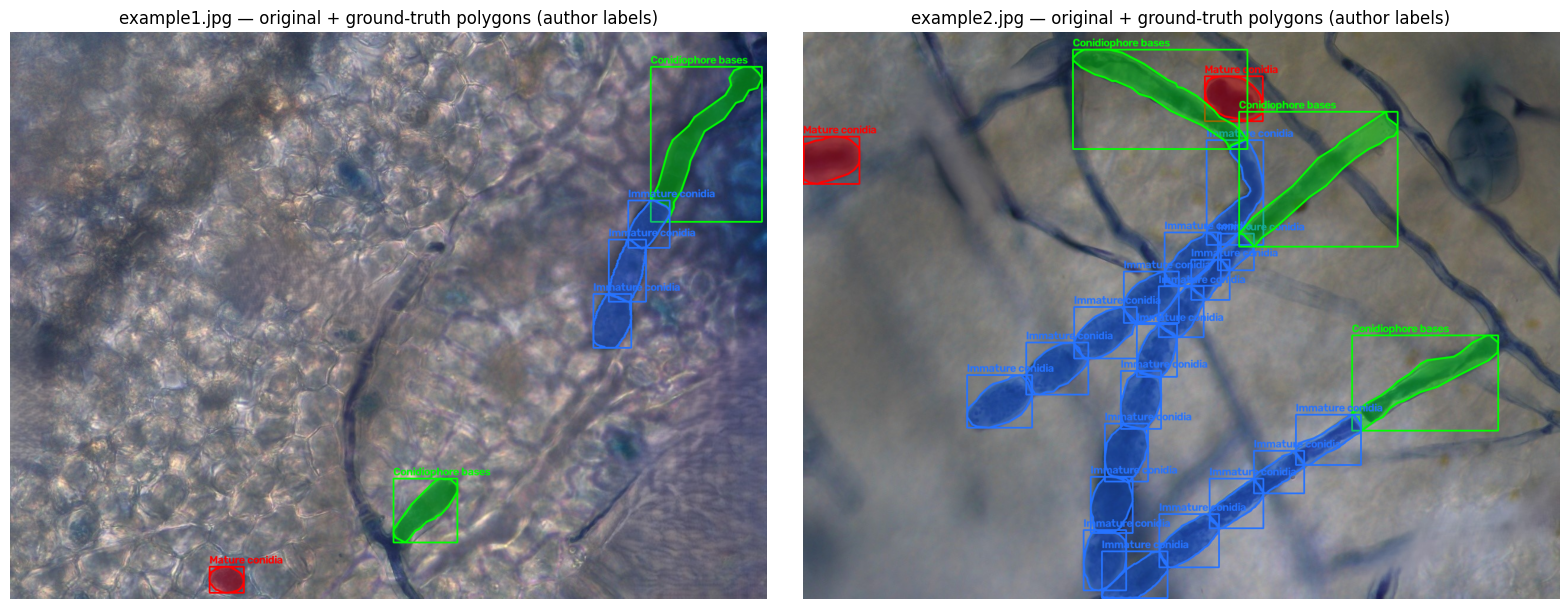

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics.utils.plotting import colors

def draw_gt(image_bgr, label_file):
    """Ground-truth YOLO polygons -> overlay (adapted from visualize_comparison.py:draw_gt)."""
    im = image_bgr.copy()
    h, w = im.shape[:2]
    for line in label_file.read_text().strip().splitlines():
        parts = line.split()
        cls = int(parts[0])
        pts = (np.array(parts[1:], dtype=float).reshape(-1, 2) * np.array([w, h])).astype(np.int32)
        color = colors(cls, True)  # BGR
        overlay = im.copy()
        cv2.fillPoly(overlay, [pts], color)
        cv2.addWeighted(overlay, 0.4, im, 0.6, 0, dst=im)
        cv2.polylines(im, [pts], True, color, 2, cv2.LINE_AA)
        x1, y1 = pts.min(axis=0)
        cv2.rectangle(im, (x1, y1), tuple(pts.max(axis=0)), color, 2)
        cv2.putText(im, NAMES[cls], (x1, max(y1 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, w / 2000), color, 2, cv2.LINE_AA)
    return im

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, stem in zip(axes, ('example1', 'example2')):
    img = cv2.imread(f'{REPO_DIR}/demo_data/images/example/{stem}.jpg')
    gt = draw_gt(img, Path(f'{REPO_DIR}/demo_data/labels/example/{stem}.txt'))
    ax.imshow(cv2.cvtColor(gt, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{stem}.jpg — original + ground-truth polygons (author labels)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Load the released SporeSeg weights

Load `weights/sporeseg_best.pt` through the authors' vendored `ultralytics` fork (`8.3.9`), which is required because the checkpoint uses the custom `SegNext_Attention` / `Segment_LSCD` modules. Print the checkpoint's own class-name mapping, task, and parameter count — expected ≈10.4 M parameters per `models/sporeseg_yolo11s.yaml` (header states 317 layers, 10,412,150 parameters).

**日本語:** リリース済み重み `weights/sporeseg_best.pt` を著者の vendored ultralytics フォークで読み込みます（カスタム モジュール必須のため）。クラス名・タスク・パラメータ数（設定ファイルのヘッダーどおり約 1,041 万）を確認します。

In [ ]:
from ultralytics import YOLO  # vendored fork already on sys.path (repo acquisition cell)
import ultralytics

print('vendored ultralytics version:', ultralytics.__version__)
model = YOLO('weights/sporeseg_best.pt')
print('task:', model.task)
print('class names (from checkpoint):', model.names)
print('parameters:', sum(p.numel() for p in model.model.parameters()))

vendored ultralytics version: 8.3.9


task: segment
class names (from checkpoint): {0: 'Immature conidia', 1: 'Conidiophore bases', 2: 'Mature conidia'}
parameters: 10412150


## 7. Inference on the demo images (author `predict.py` path)

Run the released model on both demo images with the authors' defaults (`imgsz=640`, `conf=0.25`, `iou=0.7`), as `predict.py` does. **Compatibility fix 1:** `predict.py` hard-codes `source='demo_data/images/val'`, which does not exist in the pinned tree, so the equivalent bundled folder `demo_data/images/example` is passed explicitly (the README itself describes this folder as the bundled sample set).

**日本語:** 著者の `predict.py` と同じ既定パラメータ（imgsz=640, conf=0.25, iou=0.7）でデモ画像 2 枚に推論を実行します。著者スクリプトの既定パス `demo_data/images/val` はピンしたツリーに存在しないため、同梱サンプルの实际フォルダ `demo_data/images/example` を明示的に指定します（互換修正 1）。

In [ ]:
import time, collections
import pandas as pd

rows = []
results = {}
for stem in ('example1', 'example2'):
    t0 = time.time()
    res = model.predict(source=f'demo_data/images/example/{stem}.jpg',
                        imgsz=640, conf=0.25, iou=0.7, device=DEVICE, verbose=False)[0]
    elapsed = time.time() - t0
    results[stem] = res
    per_class = collections.Counter(int(c) for c in res.boxes.cls.tolist())
    for cls_id in range(3):
        rows.append({'image': stem, 'class_id': cls_id, 'class_name': NAMES[cls_id],
                     'predicted_instances': per_class.get(cls_id, 0)})
    print(f'{stem}: {len(res.boxes)} instances in {elapsed:.1f} s  per-class={dict(sorted(per_class.items()))}')

pred_table = pd.DataFrame(rows)
pred_table

example1: 7 instances in 2.5 s  per-class={0: 3, 1: 2, 2: 2}


example2: 24 instances in 0.6 s  per-class={0: 19, 1: 3, 2: 2}


,image,class_id,class_name,predicted_instances
0,example1,0,Immature conidia,3
1,example1,1,Conidiophore bases,2
2,example1,2,Mature conidia,2
3,example2,0,Immature conidia,19
4,example2,1,Conidiophore bases,3
5,example2,2,Mature conidia,2


## 8. Show the prediction overlays

Display the model's own visualization (`result.plot()`: predicted masks + boxes + labels, Ultralytics palette) for each demo image. Compare visually with the ground-truth preview above; the next section adds the authors' side-by-side original/GT/prediction figure.

**日本語:** モデルの予測結果（マスク＋ボックス＋ラベル、`result.plot()`）を表示します。上の正解プレビューと見比べてください。

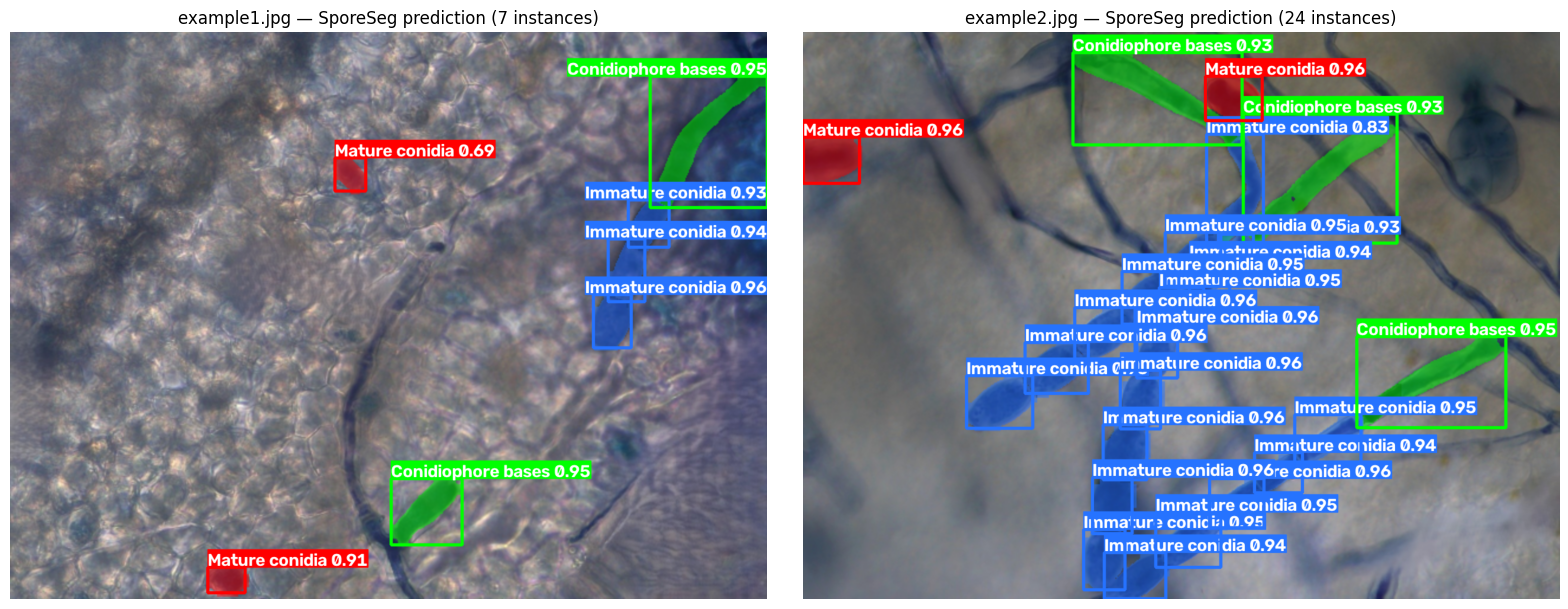

In [ ]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, stem in zip(axes, ('example1', 'example2')):
    pred_bgr = results[stem].plot()  # model's own overlay rendering
    ax.imshow(cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB))
    n = len(results[stem].boxes)
    ax.set_title(f'{stem}.jpg — SporeSeg prediction ({n} instances)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 9. Authors' original | GT | prediction comparison figure

Run the authors' standalone `visualize_comparison.py`, which concatenates original image, ground-truth annotation, and prediction into one figure per image (output to `runs/comparison/`). **Compatibility fix 1** applies again: `--source demo_data/images/example` is passed explicitly because the script's argparse default `demo_data/images/val` does not exist in the pinned tree.

**日本語:** 著者の `visualize_comparison.py` を実行し、「元画像｜正解｜予測」の 3 パネル比較図を生成します。既定パスが存在しないため `--source demo_data/images/example` を明示指定します（互換修正 1）。

In [ ]:
import subprocess, sys, glob

cmd = [sys.executable, 'visualize_comparison.py',
       '--source', 'demo_data/images/example',
       '--weights', 'weights/sporeseg_best.pt',
       '--save-dir', 'runs/comparison']
r = subprocess.run(cmd, cwd=REPO_DIR, capture_output=True, text=True, timeout=1800)
r.check_returncode()
print(r.stdout.strip())

comparison_files = sorted(glob.glob(f'{REPO_DIR}/runs/comparison/*_comparison.jpg'))
assert len(comparison_files) == 2, comparison_files
print('figures:', [f.split('/')[-1] for f in comparison_files])

[saved] runs/comparison/example1_comparison.jpg
[saved] runs/comparison/example2_comparison.jpg

Done. Comparison figures saved to /content/Sporeseg/runs/comparison
figures: ['example1_comparison.jpg', 'example2_comparison.jpg']


Display the two generated comparison figures inline. Each figure concatenates the original image, the author ground-truth rendering, and the model prediction with the same palette, so predictions can be checked against the reference annotation panel.

**日本語:** 生成した比較図（左：元画像｜中：正解｜右：予測）をノートブック内に表示します。

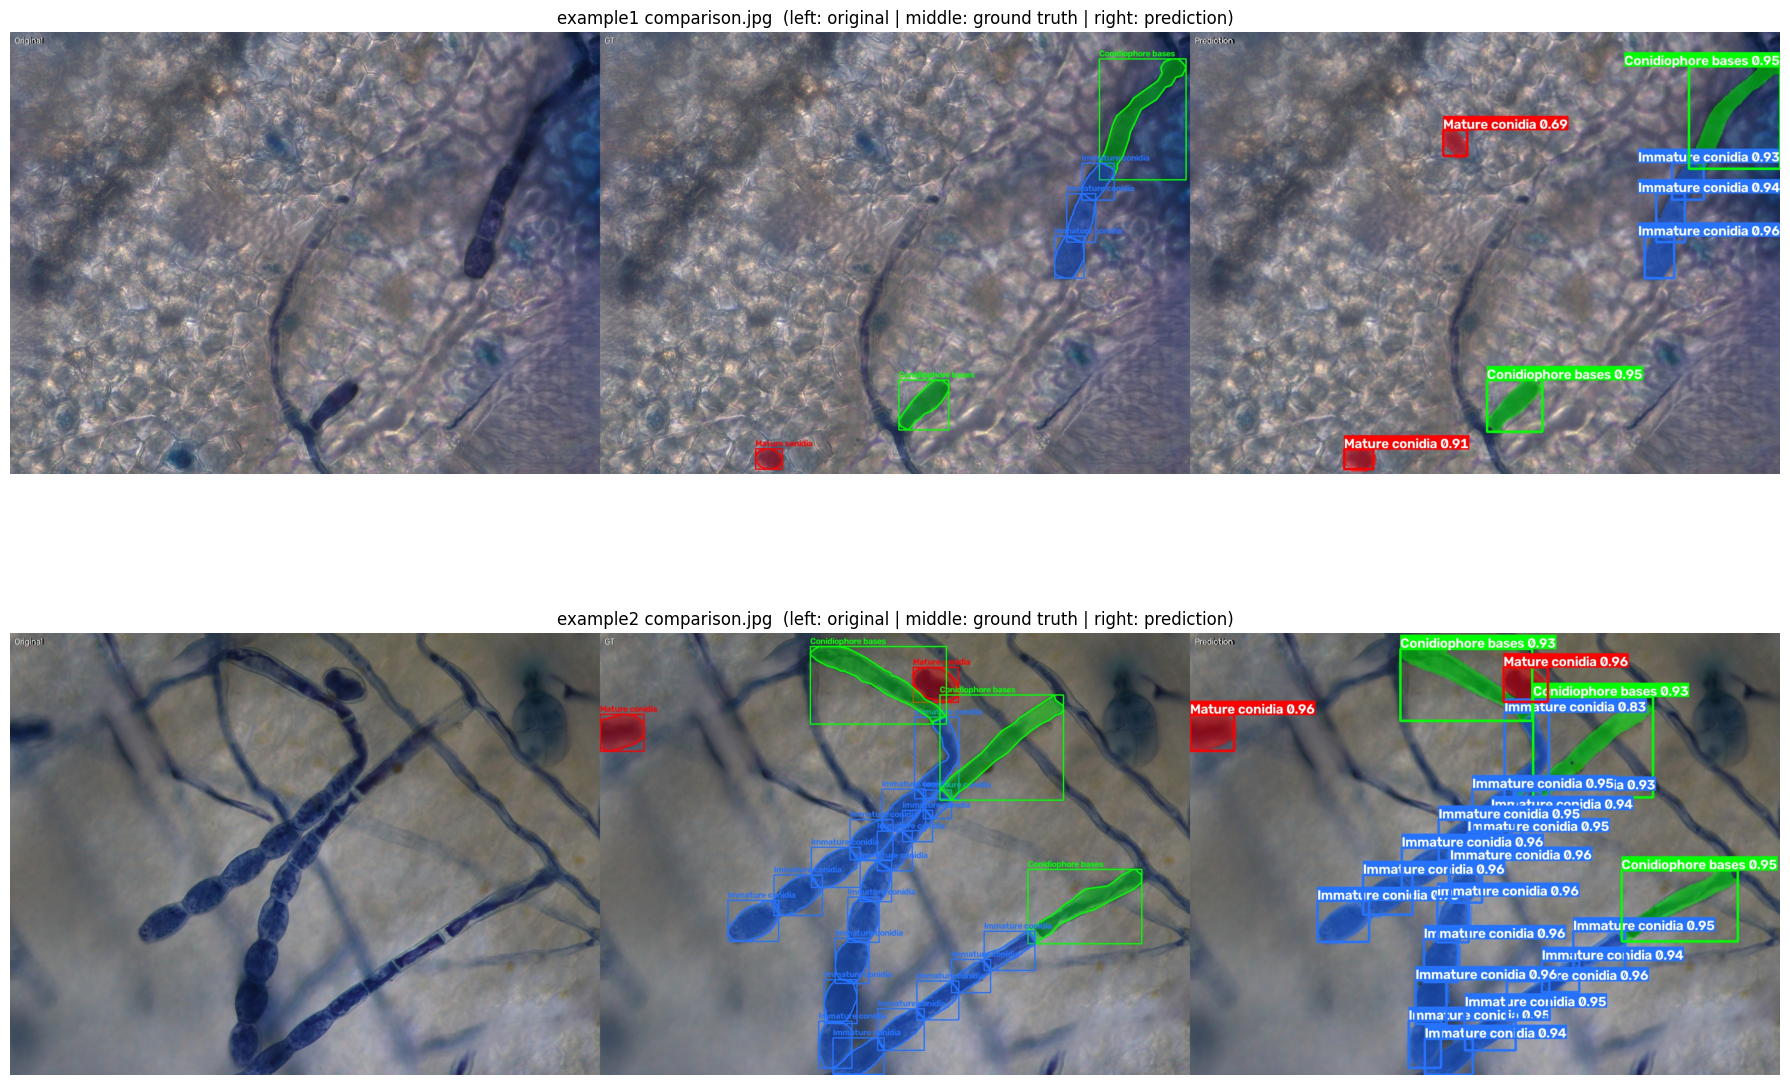

In [ ]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(18, 13))
for ax, f in zip(axes, comparison_files):
    ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
    ax.set_title(f.split('/')[-1].replace('_', ' ') + '  (left: original | middle: ground truth | right: prediction)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 10. Demo-split evaluation with the authors' `val.py`

Run the authors' `val.py` as authored (it generates an absolute-path runtime copy of `dataset/sporeseg.yaml` and evaluates `split='val'` with `conf=0.001`, `iou=0.7`, `imgsz=640`). **Compatibility fix 3:** the vendored `ultralytics/utils/metrics.py` uses `np.trapz`, which NumPy 2 removed; because the authors' `numpy<2.0.0` pin has no wheels for Colab's Python 3.13, the script runs under a one-line shim `np.trapz = np.trapezoid` — the *same* trapezoidal-integration function under its new name, so the metric computation is unchanged.

⚠️ The resulting mAP values come from **2 demo images (30 instances)** and are only a pipeline smoke test — **not** the paper's Table 1 results.

**日本語:** 著者の `val.py` をそのまま実行します。NumPy 2 で削除された `np.trapz` を `np.trapezoid`（同一関数の改名）に置き換える 1 行シムを介して実行します（互換修正 3）。得られる mAP はデモ 2 枚（30 インスタンス）によるスモークテスト値であり、論文の Table 1 ではありません。

In [ ]:
import subprocess, sys, re, time

SHIM = "import numpy as np; np.trapz = getattr(np, 'trapz', np.trapezoid); import runpy; runpy.run_path('val.py', run_name='__main__')"
t0 = time.time()
r = subprocess.run([sys.executable, '-c', SHIM], cwd=REPO_DIR, capture_output=True, text=True, timeout=1800)
r.check_returncode()
print(f'val.py completed in {time.time()-t0:.1f} s (exit 0)')

vals = re.findall(r'(box|mask)\s+mAP@(0\.5|0\.5:0\.95)\s+=\s+([\d.]+)', r.stdout)
summary = {f'{a} mAP@{b}': float(c) for a, b, c in vals}
print(r.stdout.split('=== Evaluation summary ===')[-1].strip())
assert len(summary) == 4, summary

val.py completed in 16.2 s (exit 0)
box  mAP@0.5      = 0.9950
box  mAP@0.5:0.95 = 0.8920
mask mAP@0.5      = 0.9950
mask mAP@0.5:0.95 = 0.7689


## 11. Results table and CSV export

Summarize the smoke test as a small table: per-class ground-truth instance counts (from the authors' label files) and prediction counts (from `model.predict`), plus the demo-split mAP values from `val.py`. A CSV is exported inside the Colab VM (`/content/sporeseg_demo_results.csv`) via the displayed download link.

**日本語:** クラス別の正解インスタンス数・予測数と、デモ分割の mAP を 1 つの表にまとめ、Colab 内に CSV を出力します（あくまでデモ 2 枚のスモークテスト結果です）。

In [ ]:
import collections
from pathlib import Path
import pandas as pd
from IPython.display import FileLink

rows = []
for stem in ('example1', 'example2'):
    gt = collections.Counter(int(l.split()[0]) for l in
        Path(f'{REPO_DIR}/demo_data/labels/example/{stem}.txt').read_text().strip().splitlines())
    pred = collections.Counter(int(c) for c in results[stem].boxes.cls.tolist())
    for cls_id in range(3):
        rows.append({'image': stem, 'class': NAMES[cls_id],
                     'gt_instances': gt.get(cls_id, 0),
                     'predicted_instances': pred.get(cls_id, 0)})
for k, v in summary.items():
    rows.append({'image': 'demo split (2 images)', 'class': k,
                 'gt_instances': None, 'predicted_instances': v})

demo_results = pd.DataFrame(rows)
csv_path = '/content/sporeseg_demo_results.csv'
demo_results.to_csv(csv_path, index=False)
print(demo_results.to_string(index=False))
print('\nCSV export:')
FileLink(csv_path)

                image              class  gt_instances  predicted_instances
             example1   Immature conidia           3.0               3.0000
             example1 Conidiophore bases           2.0               2.0000
             example1     Mature conidia           1.0               2.0000
             example2   Immature conidia          19.0              19.0000
             example2 Conidiophore bases           3.0               3.0000
             example2     Mature conidia           2.0               2.0000
demo split (2 images)        box mAP@0.5           NaN               0.9950
demo split (2 images)   box mAP@0.5:0.95           NaN               0.8920
demo split (2 images)       mask mAP@0.5           NaN               0.9950
demo split (2 images)  mask mAP@0.5:0.95           NaN               0.7689

CSV export:


/content/sporeseg_demo_results.csv

## Interpretation and validation record

**What was verified (this run):** the released SporeSeg checkpoint (10,412,150 parameters, exactly matching `models/sporeseg_yolo11s.yaml`) loads in the authors' vendored Ultralytics 8.3.9 fork and performs instance segmentation on the two bundled demo microscopy images; the authors' `predict.py`, `visualize_comparison.py`, and `val.py` entry points all run as authored (with the three documented compatibility fixes); on the demo split (2 images, 30 instances) the smoke-test mAP is high (box/mask mAP@0.5 ≈ 0.99), consistent with the checkpoint being trained for exactly these imaging conditions.

**What this does NOT show:** the paper's dataset is confidential and unreleased, so Table 1 accuracy/efficiency comparisons, the multi-dimensional quantification framework, and the temporal dynamics analysis remain unverified from public materials. The 2-image mAP is a pipeline sanity check only.

**日本語:** 検証できたことは、リリース済み重みが著者のフォークで正しく読み込まれ、同梱デモ画像 2 枚に対して推論・比較図・`val.py` 評価が著者コードのままで動作することです（互換修正 3 点は文書化済み）。論文の Table 1 や定量フレームワークはデータが非公開のため検証対象外です。デモ 2 枚の mAP はパイプラインの健全性確認にすぎません。

**References**
- Paper: DOI [10.1016/j.inpa.2026.10.008](https://doi.org/10.1016/j.inpa.2026.10.008), *Information Processing in Agriculture* (2026).
- Code: `YidingZhang117/Sporeseg` @ `73c930fa5d4d0968b701c945c2604f35c5b0035e` (README §3, `predict.py`, `val.py`, `visualize_comparison.py`, `models/sporeseg_yolo11s.yaml`, `dataset/sporeseg.yaml`).
- Framework: vendored Ultralytics 8.3.9 (AGPL-3.0). Weights/configs provided "for peer-review purposes" per the authors' README §5.